# **Variational Autoencoder**

![alt text](notebook-images/variational-autoencoder.png)

---

## Why do we even need **variational autoencoder** to generate new data?

* **First approach**, would be to randomly sample the data from latent space and run them through the decoder. But here's the catch. This approach won't produce useful results, mainly because the latent space is disorganised and irregular.

* **Another approach** would be to take an encoded image and then sample points that are in the neighborhood of it's latent representation. This should give us images, that resemble the original, right? Not exactly. Latent space is so poorly structured, that even nearby points often don't correspond to meaningful variations of original image. If we sample close to the original image, we end up with the same reconstruction.

> **Ideally, we want to organize the latent space**

---

## Difference between **variational autoencoder** and classic autoencoder

In a standard autoencoder, representation is a single point in the latent space. Now with **variational autoencoders**, things work a bit differently. Instead of mapping the input to the single point, the encoder converts the input into a probability distribution, that we choose to be a Gaussian. Essentially, the encoder transforms the input data into the parameters of this Gaussian. Now instead representing our image as a single point in the latent space, its represented as a Gaussian distribution. From this latent distribution, we sample points at random, and the decoder converts these sampled points back into the input space. 

We can then compute the different parts of the loss and backpropagate it through the network. But to make this possible, we have to use technique called **reparameterization** to handle the randomness outside of the network. Then the process becomes differentiable with respect to the mean and variance.

![alt text](notebook-images/reparam.png)

> **The Log-Variance Trick**: In practice (e.g., in PyTorch), the encoder's final layers do not output $\sigma$ or $\sigma^2$ directly, because linear layers can output negative values, and variance must be positive. Instead, the network is trained to output the logarithm of the variance, usually denoted as $\log(\sigma^2)$. We then retrieve $\sigma$ for the reparameterization trick using the exponential function: $\sigma = \exp(0.5 \cdot \log(\sigma^2))$. This guarantees that $\sigma$ is always positive and makes training numerically stable.

---

### **Kullback-Leibler divergence**

![alt](notebook-images/kl_div.png)

> **The role of KL Divergence**: It acts as a regularizer. While the reconstruction loss forces the network to encode information well, the **KL Divergence** forces the generated distributions to be as close to the **Standard Normal Distribution** $\mathcal{N}(0, 1)$ as possible. This prevents the network from "cheating" by shrinking the variance to zero ($\sigma \to 0$). It forces the distributions of different classes to overlap smoothly around the center of our latent space, eliminating "dead zones"

We "just" have to compute this quantity, backpropagate the combined loss, update the network's weight and repeat this process for each image in the dataset.

After this process, the VAE is able to reconstruct any digit it encounters. But that's not all - the trained VAE also allows us to generate entirely new handwritten digits that weren't part of our original dataset.

**That's awesome, but this coin has two sides:**
- VAE's tend to produce blurry images
- lack of conditioning to impose specific constraints on the generated data

> **Latent Space Continuity and Interpolation**: Because the KL divergence forces the distributions to overlap smoothly, the latent space becomes continuous. This means we can pick the latent vector for digit "1", pick the vector for digit "7", and draw a straight line between them. If we sample points along this line and decode them, we will see a smooth, frame-by-frame transformation (morphing) of a 1 into a 7.

---
### Application of Variational Autoencoders
- Generating synthetic data (data augmentation)
- Smooth editing and vectorizing data (latent space arithmetic)
- Probabilistic anomaly detection - works better than classic autoencoder. VAE not only returns reconstruction error, but it also can give us probability for particular sample to occur
- Environment compression (reinforcement learning)
---

In [40]:
import torch
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch_directml

import matplotlib.pyplot as plt

## **VAE Architecture Breakdown**

The implementation of the `VariationalAutoencoder` class differs from a standard autoencoder primarily in how it handles the latent space bottleneck. Instead of compressing the input into a single deterministic vector, the **encoder** processes the data through a shared hidden layer and then splits into two separate linear layers. One layer outputs the mean ($\mu$) and the other outputs the logarithm of the variance ($\log(\sigma^2)$), effectively representing the input as a probability distribution.

To make this random sampling process differentiable for backpropagation, the network uses the **reparameterization trick**. The `reparametrize` step first extracts the standard deviation ($\sigma$) by applying the exponential function to half of the log-variance ($\sigma = \exp(0.5 \cdot \log(\sigma^2))$). It then samples random noise ($\epsilon$) from a Standard Normal Distribution $\mathcal{N}(0, 1)$ and computes the final latent vector $z$ by scaling the noise by the standard deviation and shifting it by the mean ($z = \mu + \epsilon \cdot \sigma$).

Once the latent vector $z$ is sampled, the **decoder** processes it through a hidden layer and reconstructs the original input. Since the image pixel values are normalized, a `sigmoid` activation is applied to the final output to ensure all values stay strictly within the $[0, 1]$ boundaries. 

Finally, the **forward pass** orchestrates the entire flow. Crucially, it returns three distinct values: the reconstructed image, the mean ($\mu$), and the log-variance ($\log(\sigma^2)$). Unlike a standard autoencoder that only needs the reconstruction to calculate the error, a VAE explicitly requires these two statistical parameters to compute the Kullback-Leibler (KL) divergence and properly regularize the latent space.

In [ ]:
class VariationalAutoencoder(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20):
        super().__init__()

        self.encoder_fc = nn.Linear(input_dim, hidden_dim)

        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

        self.decoder_fc = nn.Linear(latent_dim, hidden_dim)
        self.output_out = nn.Linear(hidden_dim, input_dim)

    def encode(self, X):
        h = torch.relu(self.encoder_fc(X))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparametrize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)

        return mu + eps * std

    def decode(self, z):
        h = torch.relu(self.decoder_fc(z))
        return torch.sigmoid(self.output_out(h))

    def forward(self, X):
        mu, logvar = self.encode(X)
        z = self.reparametrize(mu, logvar)
        reconstructed = self.decode(z)

        return reconstructed, mu, logvar

## **Convolutional VAE Architecture Breakdown**

The `ConvVariationalAutoencoder` upgrades the basic architecture by integrating convolutional layers, which are vastly superior at capturing the spatial geometry and local patterns of images. The **encoder** uses a series of 2D convolutional layers to progressively downsample the input image into a deeper, smaller feature map (ending at a $32 \times 4 \times 4$ shape). Before this spatial data can be processed by the VAE bottleneck, it must be flattened into a 1D vector of 512 features.

Once flattened, the network behaves exactly like the linear VAE. The 512-dimensional vector is passed through two separate linear layers to compute the mean ($\mu$) and log-variance ($\log(\sigma^2)$). The **reparameterization trick** is then applied, sampling random noise ($\epsilon$) from a Standard Normal Distribution and combining it with the learned statistical parameters to generate the latent vector $z$.

The decoding process introduces the reverse spatial transformation. First, a linear layer expands the small latent vector $z$ back into 512 features. Crucially, this flat vector is then **reshaped (unflattened)** back into its 3D block structure ($32 \times 4 \times 4$). From there, the **decoder** utilizes transposed convolutional layers (`ConvTranspose2d`) to iteratively upsample the feature maps until it reconstructs the original $28 \times 28$ image. A `sigmoid` activation is applied at the very end to bound the pixel values between 0 and 1.

Ultimately, the **forward pass** orchestrates this flow seamlessly. By hiding the complex spatial flattening and reshaping within the `encode` and `decode` methods, the main loop remains clean and straightforward. Just like the linear version, it returns the final reconstructed image alongside $\mu$ and $\log(\sigma^2)$ so the custom loss function can accurately compute the Kullback-Leibler (KL) divergence.

In [42]:
class ConvVariationalAutoencoder(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()
        
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, stride=2, padding=1),  # -> [batch, 8, 14, 14]
            nn.ReLU(),
            nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1), # -> [batch, 16, 7, 7]
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1) # -> [batch, 32, 4, 4]
        )

        # Calculating the size of flattened tensor: 32 channels * 4 height * 4 width = 512
        self.flatten_size = 32 * 4 * 4
        
        #VAE Bottlenect
        self.fc_mu = nn.Linear(self.flatten_size, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_size, latent_dim)
        
        # Decoder
        # First we have to expand the latent space vector (20) back to 512 features
        self.decoder_input = nn.Linear(latent_dim, self.flatten_size)
        
        # Convolutional decoder (input must first be reshaped into a tensor of shape [batch, 32, 4, 4])
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=0), # -> [batch, 16, 7, 7]
            nn.ReLU(),
            nn.ConvTranspose2d(16, 8, kernel_size=3, stride=2, padding=1, output_padding=1),  # -> [batch, 8, 14, 14]
            nn.ReLU(),
            nn.ConvTranspose2d(8, 1, kernel_size=3, stride=2, padding=1, output_padding=1),   # -> [batch, 1, 28, 28]
            nn.Sigmoid()
        )

    def encode(self, x):
        x = self.encoder(x)
        
        # We flatten tensor from [batch, 32, 4, 4] to [batch, 512] so it can be fed into the Linear layers
        x = x.view(x.size(0), -1)
        
        return self.fc_mu(x), self.fc_logvar(x)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        # Expand the latent space vector (e.g., from length 20 to 512)
        z = self.decoder_input(z)
        
        # Reshape the flattened vector into a 3D block: [batch, channels, height, width]
        z = z.view(z.size(0), 32, 4, 4)
        
        # Generating the reconstructed image from the latent space representation
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)
        return reconstructed, mu, logvar

## **VAE Loss Function Breakdown**

The VAE loss function calculates the total network error by carefully balancing two competing objectives: reconstructing the original image accurately and organizing the latent space.

The first component is the **Reconstruction Loss**, calculated using Binary Cross Entropy (BCE). Since the image pixels are normalized to values between 0 and 1, BCE effectively treats them as probabilities, measuring how closely the decoder's output matches the original input. Crucially, the `reduction='sum'` parameter is used to sum the error across all pixels in the entire batch rather than averaging them. This aggregation is standard practice in VAEs to ensure the reconstruction penalty operates on the correct scale to balance the regularization term.

The second component is the **Kullback-Leibler (KL) Divergence**, which acts as the mathematical regularizer. This formula calculates how much the network's learned probability distribution—represented by the mean ($\mu$) and log-variance—deviates from a Standard Normal Distribution $\mathcal{N}(0, 1)$. In the code, the exponential function (`logvar.exp()`) is used to convert the log-variance back into raw variance for the equation. This penalty forces the distributions of different classes to overlap smoothly around the center of the latent space, preventing the network from "cheating" by shrinking the variance to zero.

Ultimately, the function returns the **sum of BCE and KLD**. During training, the optimizer must find the perfect equilibrium: compressing the data into a continuous, well-structured probability distribution (enforced by KLD) while retaining enough specific information to generate accurate and recognizable images (enforced by BCE).

In [43]:
def vae_loss_function(reconstructed, x, mu, logvar):
    BCE = torch.nn.functional.binary_cross_entropy(reconstructed, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    
    return BCE + KLD

In [44]:
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 1e-3
DEVICE = torch_directml.device(0)

In [45]:
train_dataset = datasets.MNIST(root='./data', train=True, transform=transforms.ToTensor(), download=True)
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)

In [46]:
model = ConvVariationalAutoencoder().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [47]:
model.train()

for epoch in range(EPOCHS):
    train_loss = 0.0

    for images, _ in train_dataloader:
        # images = images.view(images.size(0), -1).to(DEVICE)     It's needed for linear model
        images = images.to(DEVICE)  # For convolutional model
        reconstructed, mu, logvar = model(images)

        loss = vae_loss_function(reconstructed, images, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_loss = train_loss / len(train_dataloader.dataset)
    print(f"Epoch [{epoch + 1}/{EPOCHS}], Loss: {avg_loss:.4f}")

Epoch [1/10], Loss: 350.8482
Epoch [2/10], Loss: 273.2625
Epoch [3/10], Loss: 223.0451
Epoch [4/10], Loss: 204.4596
Epoch [5/10], Loss: 193.6746
Epoch [6/10], Loss: 185.3192
Epoch [7/10], Loss: 179.6418
Epoch [8/10], Loss: 175.6576
Epoch [9/10], Loss: 173.4091
Epoch [10/10], Loss: 172.6531


## **Generating New Data (Random Sampling)**

Because the Kullback-Leibler (KL) divergence successfully structured the VAE's latent space to closely resemble a Standard Normal Distribution, we can now generate entirely new, original data by bypassing the encoder completely.

The process begins by setting the model to evaluation mode and disabling gradient calculations, which is standard practice for efficient memory usage during inference. Instead of encoding a real image, we directly sample a random 20-dimensional vector from a Standard Normal Distribution $\mathcal{N}(0, 1)$. This mathematical noise acts as a random set of coordinates within the dense, continuous center of our latent space.

We then feed this random vector directly into the **decoder**. Because the decoder was trained to map continuous points in this space to meaningful visual features, it interprets these random coordinates and synthesizes a brand new, previously unseen digit. 

Finally, the network's output tensor is reshaped back into a 2D spatial grid ($28 \times 28$ pixels), transferred to the CPU, and converted into a NumPy array so Matplotlib can render it as a grayscale image. This perfectly demonstrates the ultimate generative capability of a Variational Autoencoder: transforming pure random noise into structured, realistic visual data.

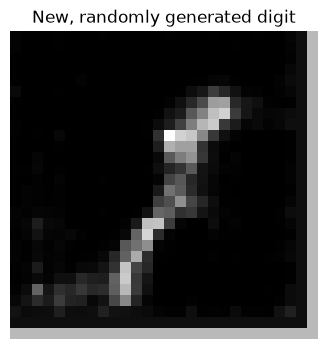

In [48]:
model.eval()
with torch.no_grad():
    z_random = torch.randn(1, 20).to(DEVICE)
    generated_image = model.decode(z_random)
    generated_image = generated_image.view(28, 28).cpu().numpy()

plt.figure(figsize=(4, 4))
plt.imshow(generated_image, cmap='gray')
plt.title('New, randomly generated digit')
plt.axis('Off')
plt.show()

## **Latent Space Interpolation (Morphing)**

One of the most powerful properties of a Variational Autoencoder is the continuity of its latent space. Because the KL divergence forces distributions to overlap smoothly, we can pick two distinct images, find their coordinates in the latent space, and draw a mathematical straight line between them. Moving along this line produces a seamless visual transition (morphing) from the first image to the second.

The process begins by extracting two real images from a data batch. Depending on the model architecture, the input tensor is preprocessed—either flattened into a 1D vector for a linear model or expanded with a batch dimension using `unsqueeze(0)` for a convolutional model. These images are then passed through the encoder. Crucially, we only extract their mean vectors ($\mu_A$ and $\mu_B$) and completely ignore the log-variance. By doing so, we bypass the random noise and secure exact, deterministic starting and ending coordinates in the latent space.

Next, we define the number of steps (frames) for our animation and generate a sequence of mixing weights ($\alpha$) ranging from 0.0 to 1.0. Inside the loop, we perform linear interpolation. For every step, a new intermediate latent vector is calculated using the formula $z = (1 - \alpha) \cdot \mu_A + \alpha \cdot \mu_B$. When $\alpha = 0$, we are exactly at the first digit; as $\alpha$ gradually increases, we move smoothly toward the second digit.

Finally, each intermediate vector is fed into the **decoder**. In a standard autoencoder, these midway points would likely decode into meaningless noise because of "dead zones" in the latent space. However, in a VAE, the decoder successfully interprets every single step, generating a fluid, frame-by-frame visual fusion of the two digits. The resulting tensors are reshaped back into 2D grids and plotted side-by-side, perfectly illustrating the continuous nature of the learned representation.

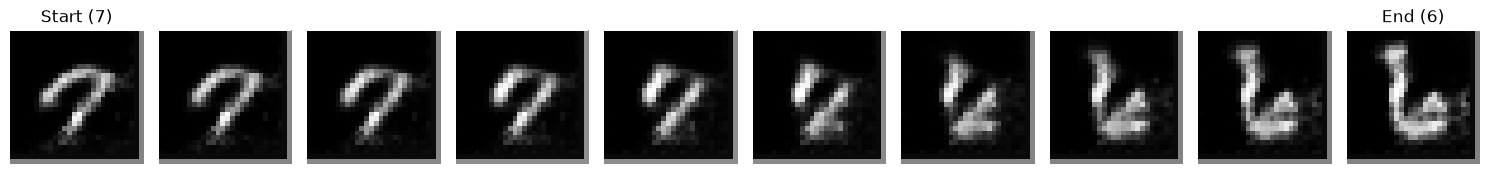

In [49]:
model.eval()
with torch.no_grad():
    dataiter = iter(train_dataloader)
    images, labels = next(dataiter)

    # For linear model
    # img_A = images[0].view(1, -1).to(DEVICE)
    # img_B = images[1].view(1, -1).to(DEVICE)

    # For convolutional model
    img_A = images[0].unsqueeze(0).to(DEVICE)
    img_B = images[1].unsqueeze(0).to(DEVICE)

    mu_A, _ = model.encode(img_A)
    mu_B, _ = model.encode(img_B)

    STEPS = 10

    alphas = torch.linspace(0, 1, STEPS).to(DEVICE)

    fig, axes = plt.subplots(1, STEPS, figsize=(15, 3))

    for i, alpha in enumerate(alphas):
        z_interp = (1 - alpha) * mu_A + alpha * mu_B
        img_interp = model.decode(z_interp).view(28, 28).cpu().numpy()
        axes[i].imshow(img_interp, cmap='gray')
        axes[i].axis('Off')

        if i == 0:
            axes[i].set_title(f"Start ({labels[0].item()})")
        elif i == STEPS - 1:
            axes[i].set_title(f"End ({labels[1].item()})")

plt.tight_layout()
plt.show()

## **Model Output Analysis & Conclusions**

### 1. New, Randomly Generated Digit (Random Sampling)
* **Output Interpretation:** The first image presents the decoded result of a completely random noise vector sampled from a Standard Normal Distribution[cite: 3].
* **Conclusions:** This result proves that the decoder has successfully learned to map abstract mathematical coordinates to concrete visual features[cite: 3]. The generated structure resembles a handwritten character, though it is somewhat blurry and looks like a fusion of several different shapes (e.g., a '1', a '3', or an 'S'). This is a classic side effect of the VAE architecture[cite: 3]. Because the KL divergence forces the distributions of different classes to overlap in the center of the latent space, the model often generates "safe," averaged, and unsharp representations to minimize the overall reconstruction error.

### 2. Latent Space Interpolation (Morphing)
* **Output Interpretation:** The second image is a sequence of ten frames visualizing a mathematical path (linear interpolation) drawn in the latent space between a vector representing the digit "7" and a vector representing the digit "6".
* **Conclusions:** This frame sequence is the ultimate proof that the model's latent space is entirely continuous. The model does not abruptly snap from one shape to another, nor does it generate meaningless noise in the intermediate frames. Instead, we observe a smooth geometric transformation: the top stroke of the seven slowly lowers and rounds out, while the bottom stem gradually curves inward to form the closed loop of the six. The lack of "dead zones" is a direct result of using the KL divergence as a regularizer during training.